In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Da cai dat thanh cong!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)


Da cai dat thanh cong!
Pandas: 3.1.0
Scikit-learn: 1.9.1


In [2]:
# BUOC 1: DOC DU LIEU KHACH SAN

import pandas as pd

# Duong dan bo du lieu
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"

# Doc du lieu
df = pd.read_csv(url)

# Luu du lieu ve thu muc du an
df.to_csv("hotels.csv", index=False)

# Kiem tra kich thuoc du lieu
print("So dong:", df.shape[0])
print("So cot:", df.shape[1])

# Hien thi 5 dong dau tien
display(df.head())

So dong: 119390
So cot: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
# BUOC 2: PHAN TICH DU LIEU

print("THONG TIN DU LIEU")
print(df.info())

print("\nSO LUONG KHACH HUY PHONG:")
print(df["is_canceled"].value_counts())

print("\nTY LE HUY PHONG (%):")
print(df["is_canceled"].value_counts(normalize=True) * 100)


THONG TIN DU LIEU
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal     

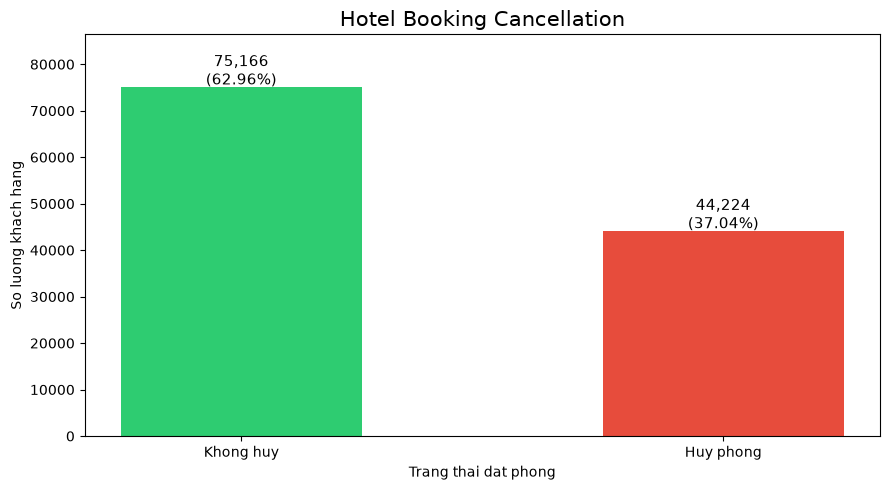

In [4]:
# BUOC 3: VE BIEU DO TY LE HUY PHONG

import matplotlib.pyplot as plt

# Dem so luong dat phong theo trang thai
counts = df["is_canceled"].value_counts().sort_index()

# Tinh ty le phan tram
percentages = counts / counts.sum() * 100

# Tao bieu do
plt.figure(figsize=(9, 5))

bars = plt.bar(
    ["Khong huy", "Huy phong"],
    counts.values,
    color=["#2ecc71", "#e74c3c"],
    width=0.5
)

# Hien thi so luong va ty le
for bar, count, pct in zip(bars, counts.values, percentages.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 500,
        f"{count:,}\n({pct:.2f}%)",
        ha="center",
        fontsize=11
    )

plt.title("Hotel Booking Cancellation", fontsize=15)
plt.xlabel("Trang thai dat phong")
plt.ylabel("So luong khach hang")
plt.ylim(0, counts.max() * 1.15)

plt.tight_layout()
plt.show()

TY LE HUY PHONG THEO LOAI KHACH SAN:
hotel
City Hotel      41.726963
Resort Hotel    27.763355
Name: is_canceled, dtype: float64


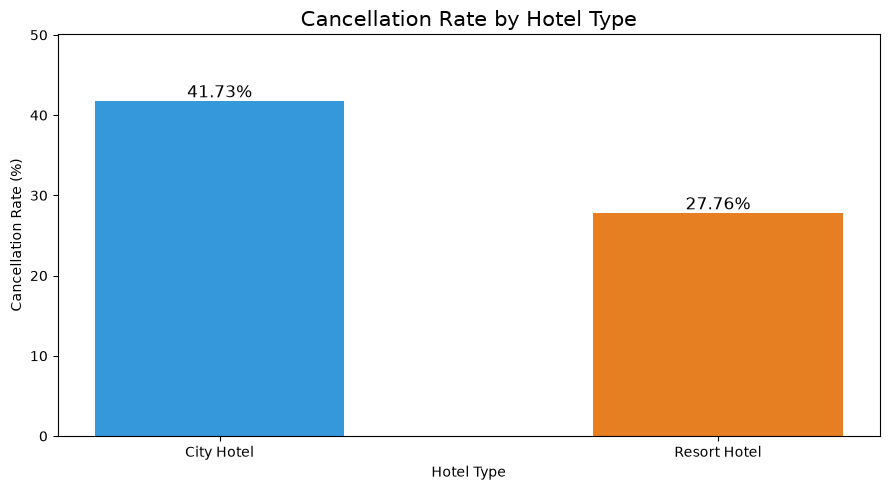

In [5]:
# BUOC 4: SO SANH TY LE HUY PHONG GIUA CAC KHACH SAN

import matplotlib.pyplot as plt

# Tinh ty le huy phong theo loai khach san
hotel_cancel = df.groupby("hotel")["is_canceled"].mean() * 100

# Hien thi ket qua
print("TY LE HUY PHONG THEO LOAI KHACH SAN:")
print(hotel_cancel)

# Ve bieu do
plt.figure(figsize=(9, 5))

bars = plt.bar(
    hotel_cancel.index,
    hotel_cancel.values,
    color=["#3498db", "#e67e22"],
    width=0.5
)

# Hien thi phan tram tren moi cot
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.2f}%",
        ha="center",
        fontsize=12
    )

plt.title("Cancellation Rate by Hotel Type", fontsize=15)
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, hotel_cancel.max() * 1.2)

plt.tight_layout()
plt.show()

TY LE HUY PHONG THEO THOI GIAN DAT TRUOC:
lead_time_group
0-7 ngay          9.632331
8-30 ngay        27.863924
31-90 ngay       37.698372
91-180 ngay      44.710466
Tren 180 ngay    57.010368
Name: is_canceled, dtype: float64


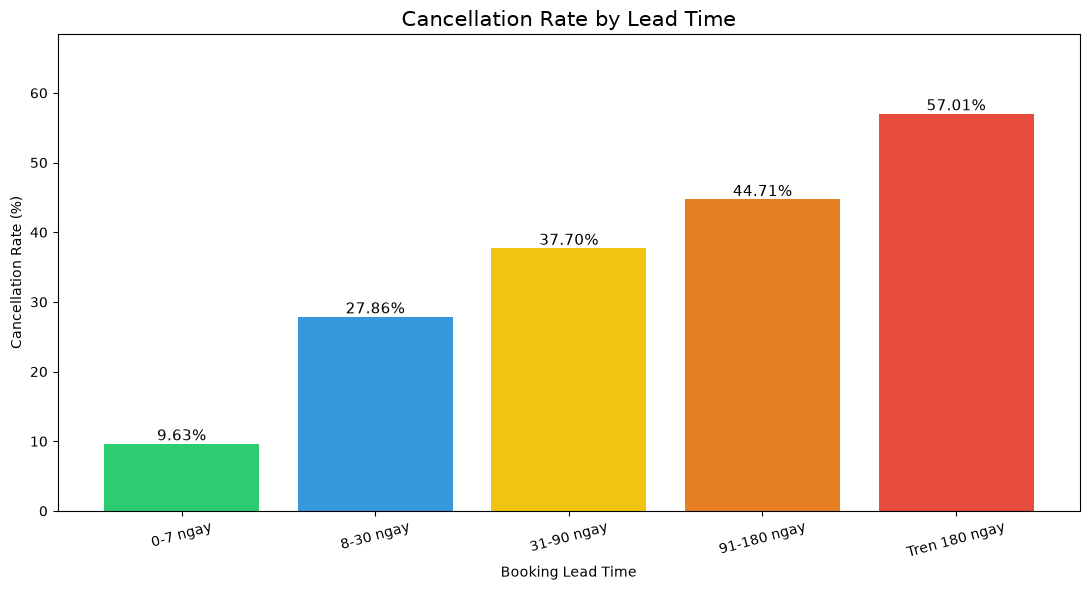

In [6]:
# BUOC 5: PHAN TICH THOI GIAN DAT PHONG TRUOC

import pandas as pd
import matplotlib.pyplot as plt

# Chia khach hang thanh 5 nhom theo thoi gian dat truoc
bins = [-1, 7, 30, 90, 180, float("inf")]

labels = [
    "0-7 ngay",
    "8-30 ngay",
    "31-90 ngay",
    "91-180 ngay",
    "Tren 180 ngay"
]

# Tao cot phan nhom
df["lead_time_group"] = pd.cut(
    df["lead_time"],
    bins=bins,
    labels=labels
)

# Tinh ty le huy phong tung nhom
lead_cancel = (
    df.groupby("lead_time_group", observed=True)["is_canceled"]
    .mean() * 100
)

# Hien thi ket qua
print("TY LE HUY PHONG THEO THOI GIAN DAT TRUOC:")
print(lead_cancel)

# Ve bieu do
plt.figure(figsize=(11, 6))

bars = plt.bar(
    lead_cancel.index,
    lead_cancel.values,
    color=["#2ecc71", "#3498db", "#f1c40f", "#e67e22", "#e74c3c"]
)

# Hien thi ty le tren cot
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.2f}%",
        ha="center",
        fontsize=11
    )

plt.title("Cancellation Rate by Lead Time", fontsize=15)
plt.xlabel("Booking Lead Time")
plt.ylabel("Cancellation Rate (%)")

plt.ylim(0, lead_cancel.max() * 1.2)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [7]:
# BUOC 6.1: KIEM TRA DU LIEU

# Kiem tra kich thuoc du lieu
print("KICH THUOC DU LIEU:")
print(df.shape)

# Kiem tra gia tri bi thieu
print("\nSO GIA TRI BI THIEU:")
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))

# Kiem tra du lieu trung lap
print("\nSO DONG TRUNG LAP:")
print(df.duplicated().sum())

# Kiem tra kieu du lieu
print("\nKIEU DU LIEU:")
print(df.dtypes)

KICH THUOC DU LIEU:
(119390, 33)

SO GIA TRI BI THIEU:
company     112593
agent        16340
country        488
children         4
dtype: int64

SO DONG TRUNG LAP:
31994

KIEU DU LIEU:
hotel                                  str
is_canceled                          int64
lead_time                            int64
arrival_date_year                    int64
arrival_date_month                     str
arrival_date_week_number             int64
arrival_date_day_of_month            int64
stays_in_weekend_nights              int64
stays_in_week_nights                 int64
adults                               int64
children                           float64
babies                               int64
meal                                   str
country                                str
market_segment                         str
distribution_channel                   str
is_repeated_guest                    int64
previous_cancellations               int64
previous_bookings_not_canceled       int6

In [8]:
# BUOC 6.2: XU LY GIA TRI BI THIEU

# Tao ban sao de giu nguyen du lieu goc
df_clean = df.copy()

# Xu ly cot so luong tre em
df_clean["children"] = df_clean["children"].fillna(0)

# Xu ly cac cot du lieu phan loai
for col in ["country", "agent", "company"]:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .fillna("Unknown")
    )

# Kiem tra lai
print("SO GIA TRI THIEU SAU KHI XU LY:")
print(df_clean.isnull().sum().sum())

print("\nKICH THUOC DU LIEU SAU KHI XU LY:")
print(df_clean.shape)

print("\n5 DONG DU LIEU DA XU LY:")
display(df_clean.head())

SO GIA TRI THIEU SAU KHI XU LY:
0

KICH THUOC DU LIEU SAU KHI XU LY:
(119390, 33)

5 DONG DU LIEU DA XU LY:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,lead_time_group
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Unknown,Unknown,0,Transient,0.0,0,0,Check-Out,2015-07-01,Tren 180 ngay
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Unknown,Unknown,0,Transient,0.0,0,0,Check-Out,2015-07-01,Tren 180 ngay
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Unknown,Unknown,0,Transient,75.0,0,0,Check-Out,2015-07-02,0-7 ngay
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,304.0,Unknown,0,Transient,75.0,0,0,Check-Out,2015-07-02,8-30 ngay
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,240.0,Unknown,0,Transient,98.0,0,1,Check-Out,2015-07-03,8-30 ngay


In [9]:
# BUOC 7: KIEM TRA KET QUA

print("Du lieu goc:", df.shape)
print("Du lieu da xu ly:", df_clean.shape)

print("\nGia tri thieu con lai:")
print(df_clean.isnull().sum().sum())

print("\nTy le huy phong:")
print(df_clean["is_canceled"].value_counts(normalize=True) * 100)

Du lieu goc: (119390, 33)
Du lieu da xu ly: (119390, 33)

Gia tri thieu con lai:
0

Ty le huy phong:
is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64


In [10]:
# BUOC 8: CHIA DU LIEU TRAIN VA TEST

from sklearn.model_selection import train_test_split

# Chon cac dac trung dau vao
features = [
    "hotel",
    "lead_time",
    "arrival_date_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "meal",
    "market_segment",
    "distribution_channel",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "reserved_room_type",
    "deposit_type",
    "customer_type",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

# X: Du lieu dau vao
X = df_clean[features]

# y: Ket qua can du doan
y = df_clean["is_canceled"]

# Chia 80% Train va 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Hien thi ket qua
print("CHIA DU LIEU THANH CONG!")

print("\nTap Train:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTap Test:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

CHIA DU LIEU THANH CONG!

Tap Train:
X_train: (95512, 19)
y_train: (95512,)

Tap Test:
X_test: (23878, 19)
y_test: (23878,)


In [11]:
# BUOC 9: HUAN LUYEN MO HINH LOGISTIC REGRESSION

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Cac cot du lieu dang chu
categorical_cols = [
    "hotel",
    "arrival_date_month",
    "meal",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "deposit_type",
    "customer_type"
]

# Cac cot du lieu dang so
numerical_cols = [
    col for col in features
    if col not in categorical_cols
]

# Tien xu ly du lieu
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

# Tao mo hinh Logistic Regression
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

# Huan luyen mo hinh
print("Dang huan luyen mo hinh...")

logistic_model.fit(X_train, y_train)

print("HUAN LUYEN THANH CONG!")

Dang huan luyen mo hinh...
HUAN LUYEN THANH CONG!


In [12]:
# BUOC 10: DANH GIA MO HINH

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Du doan tren tap Test
y_pred = logistic_model.predict(X_test)

# Tinh cac chi so
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Hien thi ket qua
print("KET QUA DANH GIA LOGISTIC REGRESSION")

print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1-score:  {f1 * 100:.2f}%")

print("\nBAO CAO PHAN LOAI:")
print(classification_report(y_test, y_pred))

KET QUA DANH GIA LOGISTIC REGRESSION
Accuracy:  80.79%
Precision: 84.86%
Recall:    58.60%
F1-score:  69.32%

BAO CAO PHAN LOAI:
              precision    recall  f1-score   support

           0       0.79      0.94      0.86     15033
           1       0.85      0.59      0.69      8845

    accuracy                           0.81     23878
   macro avg       0.82      0.76      0.78     23878
weighted avg       0.81      0.81      0.80     23878



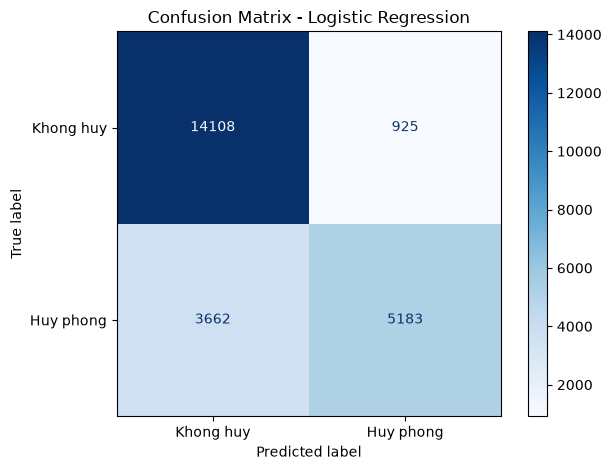

In [13]:
# BUOC 11: VE MA TRAN NHAM LAN

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Tao ma tran nham lan
cm = confusion_matrix(y_test, y_pred)

# Ve bieu do
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Khong huy", "Huy phong"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

In [14]:
# BUOC 12: HUAN LUYEN DECISION TREE VA RANDOM FOREST

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# MO HINH 2: DECISION TREE
tree_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=20,
        random_state=42
    ))
])

print("Dang huan luyen Decision Tree...")
tree_model.fit(X_train, y_train)
print("Decision Tree thanh cong!")


# MO HINH 3: RANDOM FOREST
rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

print("\nDang huan luyen Random Forest...")
rf_model.fit(X_train, y_train)
print("Random Forest thanh cong!")

Dang huan luyen Decision Tree...
Decision Tree thanh cong!

Dang huan luyen Random Forest...
Random Forest thanh cong!


In [15]:
# BUOC 13: SO SANH 3 MO HINH

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions)
    })

# Tao bang so sanh
results_df = pd.DataFrame(results)

# Chuyen sang phan tram
for col in ["Accuracy", "Precision", "Recall", "F1-score"]:
    results_df[col] = results_df[col] * 100

print("BANG SO SANH 3 MO HINH MACHINE LEARNING")

display(results_df.round(2))

BANG SO SANH 3 MO HINH MACHINE LEARNING


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,80.79,84.86,58.60,69.32
1,Decision Tree,81.60,83.17,63.09,71.75
2,Random Forest,82.07,85.70,61.92,71.90


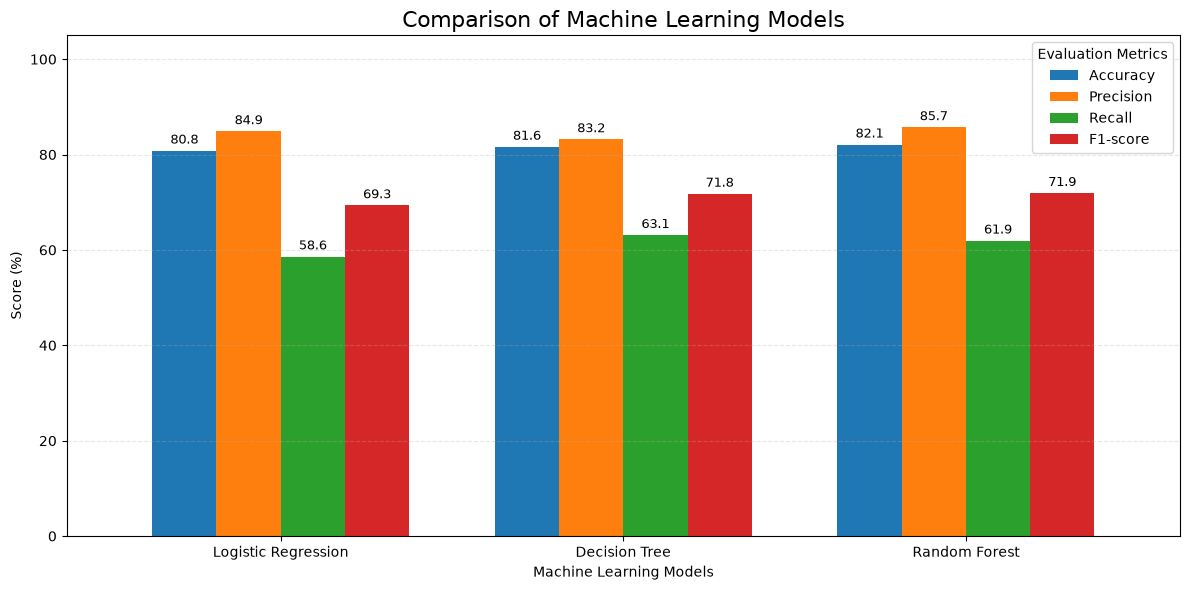

Da luu bieu do comparison_models.png


In [16]:
# BUOC 14: VE BIEU DO SO SANH 3 MO HINH

import matplotlib.pyplot as plt

# Cac chi so danh gia
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

# Tao bieu do so sanh
ax = results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

# Tieu de va nhan
plt.title(
    "Comparison of Machine Learning Models",
    fontsize=16
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Score (%)")

plt.xticks(rotation=0)
plt.ylim(0, 105)

plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Hien thi gia tri tren cac cot
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()

# Luu bieu do de dua vao bao cao
plt.savefig(
    "comparison_models.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Da luu bieu do comparison_models.png")

In [17]:
# XEP HANG MO HINH THEO F1-SCORE

ranking = results_df.sort_values(
    by="F1-score",
    ascending=False
)

print("BANG XEP HANG MO HINH:")
display(ranking.round(2))

print("\nMO HINH CO F1-SCORE CAO NHAT:")
print(ranking.iloc[0]["Model"])

print("\nF1-SCORE:")
print(f'{ranking.iloc[0]["F1-score"]:.2f}%')

BANG XEP HANG MO HINH:


,Model,Accuracy,Precision,Recall,F1-score
2,Random Forest,82.07,85.70,61.92,71.90
1,Decision Tree,81.60,83.17,63.09,71.75
0,Logistic Regression,80.79,84.86,58.60,69.32



MO HINH CO F1-SCORE CAO NHAT:
Random Forest

F1-SCORE:
71.90%


In [18]:
# BUOC 15: CROSS VALIDATION

from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# Tao bo chia 3-Fold
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Danh sach 3 mo hinh
models_cv = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "Random Forest": rf_model
}

# Luu ket qua
cv_results = []

# Danh gia tung mo hinh
for name, model in models_cv.items():

    print(f"Dang danh gia {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        },
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean() * 100,
        "Precision": scores["test_precision"].mean() * 100,
        "Recall": scores["test_recall"].mean() * 100,
        "F1-score": scores["test_f1"].mean() * 100
    })

# Tao bang ket qua
cv_df = pd.DataFrame(cv_results)

# Sap xep theo F1-score
cv_df = cv_df.sort_values(
    by="F1-score",
    ascending=False
)

print("\nKET QUA CROSS VALIDATION:")
display(cv_df.round(2))

Dang danh gia Logistic Regression...
Dang danh gia Decision Tree...
Dang danh gia Random Forest...

KET QUA CROSS VALIDATION:


,Model,Accuracy,Precision,Recall,F1-score
1,Decision Tree,81.62,82.92,63.46,71.90
2,Random Forest,82.00,85.29,62.11,71.87
0,Logistic Regression,80.57,84.23,58.51,69.05


In [19]:
# TIM MO HINH TOT NHAT THEO F1-SCORE

best_name = cv_df.iloc[0]["Model"]
best_f1 = cv_df.iloc[0]["F1-score"]

print("MO HINH CO F1-SCORE CAO NHAT:")
print(best_name)

print("\nF1-SCORE TRUNG BINH:")
print(f"{best_f1:.2f}%")

MO HINH CO F1-SCORE CAO NHAT:
Decision Tree

F1-SCORE TRUNG BINH:
71.90%


In [20]:
# BUOC 15.4: TOI UU DECISION TREE

from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

# Cac tham so can thu nghiem
param_grid = {
    "classifier__max_depth": [8, 12, 16],
    "classifier__min_samples_leaf": [10, 20, 40],
    "classifier__min_samples_split": [2, 10]
}

# Tim bo tham so tot nhat
grid_tree = GridSearchCV(
    estimator=clone(tree_model),
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=1,
    verbose=1
)

print("DANG TOI UU DECISION TREE...")

# Huan luyen va tim tham so
grid_tree.fit(X_train, y_train)

# Lay mo hinh tot nhat
best_tree = grid_tree.best_estimator_

print("\nTOI UU HOAN THANH!")

print("\nBO THAM SO TOT NHAT:")
print(grid_tree.best_params_)

print("\nF1-SCORE CROSS VALIDATION TOT NHAT:")
print(f"{grid_tree.best_score_ * 100:.2f}%")

DANG TOI UU DECISION TREE...
Fitting 3 folds for each of 18 candidates, totalling 54 fits

TOI UU HOAN THANH!

BO THAM SO TOT NHAT:
{'classifier__max_depth': 16, 'classifier__min_samples_leaf': 20, 'classifier__min_samples_split': 2}

F1-SCORE CROSS VALIDATION TOT NHAT:
73.35%


In [21]:
# DANH GIA DECISION TREE SAU TOI UU

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Du doan tren tap Test
y_pred_best = best_tree.predict(X_test)

print("KET QUA DECISION TREE SAU TOI UU")

print(
    f"Accuracy: "
    f"{accuracy_score(y_test, y_pred_best) * 100:.2f}%"
)

print(
    f"Precision: "
    f"{precision_score(y_test, y_pred_best) * 100:.2f}%"
)

print(
    f"Recall: "
    f"{recall_score(y_test, y_pred_best) * 100:.2f}%"
)

print(
    f"F1-score: "
    f"{f1_score(y_test, y_pred_best) * 100:.2f}%"
)

KET QUA DECISION TREE SAU TOI UU
Accuracy: 81.92%
Precision: 81.02%
Recall: 66.87%
F1-score: 73.27%


In [22]:
# BUOC 16: LUU MO HINH MACHINE LEARNING

import joblib
from pathlib import Path

# Lay cac gia tri lua chon cho du lieu dang chu
category_options = {}

for col in categorical_cols:
    category_options[col] = sorted(
        X_train[col].dropna().astype(str).unique().tolist()
    )

# Lay gia tri mac dinh cho du lieu dang so
numeric_defaults = {}

for col in numerical_cols:
    numeric_defaults[col] = float(X_train[col].median())

# Dong goi mo hinh va thong tin dau vao
model_package = {
    "model": best_tree,
    "features": features,
    "categorical_cols": categorical_cols,
    "numerical_cols": numerical_cols,
    "category_options": category_options,
    "numeric_defaults": numeric_defaults
}

# Luu mo hinh
model_path = Path("hotel_cancellation_model.joblib")

joblib.dump(model_package, model_path)

print("LUU MO HINH THANH CONG!")
print("Duong dan:", model_path.resolve())

LUU MO HINH THANH CONG!
Duong dan: C:\Users\LENOVO LOQ\MachineLearning_HotelBooking\hotel_cancellation_model.joblib


In [23]:
# KIEM TRA FILE MO HINH

import joblib

# Tai mo hinh da luu
loaded_package = joblib.load(
    "hotel_cancellation_model.joblib"
)

loaded_model = loaded_package["model"]

# Lay mot mau trong tap Test
sample = X_test.iloc[[0]][loaded_package["features"]]

# Du doan
prediction = loaded_model.predict(sample)[0]

# Xac suat huy phong
probability = loaded_model.predict_proba(sample)[0][1]

print("TAI MO HINH THANH CONG!")

print("\nKET QUA DU DOAN:")

if prediction == 1:
    print("Khach hang co kha nang huy phong")
else:
    print("Khach hang co kha nang khong huy phong")

print(f"Xac suat huy phong uoc tinh: {probability * 100:.2f}%")

print("Ket qua thuc te:", y_test.iloc[0])

TAI MO HINH THANH CONG!

KET QUA DU DOAN:
Khach hang co kha nang khong huy phong
Xac suat huy phong uoc tinh: 24.58%
Ket qua thuc te: 0
